# Case Study 2: Wine Quality Assessment Using Physicochemical Properties

**Objective:** Explore the wine quality dataset, identify laboratory measurements associated with quality, build a multiple linear regression model, and evaluate whether it is suitable for quality screening.

**Dataset:** UCI Wine Quality dataset. The supplied ZIP contains `winequality-red.csv` and `winequality-white.csv`.

**Dataset choice:** This notebook combines red and white wine records for the main analysis and adds a `wine_type` label for describing the dataset only. The regression model uses the **11 physicochemical attributes** specified in the assignment; `wine_type` is not used as a predictor.

> Run the notebook from top to bottom. If the ZIP is not found in Google Colab, the data-loading cell will ask you to upload it.

## 1. Import libraries

In [1]:
import os
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the wine dataset
The supplied ZIP includes separate red and white wine CSV files. They use semicolons (`;`) between values, so `sep=';'` is required.

In [2]:
ZIP_PATH = "wine+quality.zip"

# In Google Colab, upload the ZIP if it is not already present.
if not os.path.exists(ZIP_PATH):
    try:
        from google.colab import files
        print("Upload the supplied wine+quality.zip file.")
        uploaded = files.upload()
        zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
        if zip_candidates:
            ZIP_PATH = zip_candidates[0]
    except ImportError:
        pass

if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        red_file = next((n for n in z.namelist() if n.endswith("winequality-red.csv")), None)
        white_file = next((n for n in z.namelist() if n.endswith("winequality-white.csv")), None)
        if red_file is None or white_file is None:
            raise FileNotFoundError("ZIP must contain winequality-red.csv and winequality-white.csv.")
        red = pd.read_csv(z.open(red_file), sep=";")
        white = pd.read_csv(z.open(white_file), sep=";")
else:
    # Also support uploading/extracting the CSV files separately.
    if os.path.exists("winequality-red.csv") and os.path.exists("winequality-white.csv"):
        red = pd.read_csv("winequality-red.csv", sep=";")
        white = pd.read_csv("winequality-white.csv", sep=";")
    else:
        raise FileNotFoundError("Upload wine+quality.zip or both wine quality CSV files.")

red["wine_type"] = "red"
white["wine_type"] = "white"
df = pd.concat([red, white], ignore_index=True)

print("Red wine records:", len(red))
print("White wine records:", len(white))
print("Combined dataset shape:", df.shape)
display(df.head())

Red wine records: 1599
White wine records: 4898
Combined dataset shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,red
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5,red
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5,red
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6,red
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,red


## 3. Inspect and prepare the data
Check data types, missing values, duplicates, and basic statistics. The supplied dataset is generally clean; we report what is actually found instead of assuming problems exist.

In [3]:
print("Dataset information:")
display(df.dtypes.to_frame("Data type"))
print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Summary statistics:")
display(df.describe().T)

Dataset information:


,Data type
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Missing values per column:


,Missing values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicate rows: 1177
Summary statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,"6,497.0000",7.2153,1.2964,3.8000,6.4000,7.0000,7.7000,15.9000
volatile acidity,"6,497.0000",0.3397,0.1646,0.0800,0.2300,0.2900,0.4000,1.5800
citric acid,"6,497.0000",0.3186,0.1453,0.0000,0.2500,0.3100,0.3900,1.6600
residual sugar,"6,497.0000",5.4432,4.7578,0.6000,1.8000,3.0000,8.1000,65.8000
chlorides,"6,497.0000",0.0560,0.0350,0.0090,0.0380,0.0470,0.0650,0.6110
free sulfur dioxide,"6,497.0000",30.5253,17.7494,1.0000,17.0000,29.0000,41.0000,289.0000
total sulfur dioxide,"6,497.0000",115.7446,56.5219,6.0000,77.0000,118.0000,156.0000,440.0000
density,"6,497.0000",0.9947,0.0030,0.9871,0.9923,0.9949,0.9970,1.0390
pH,"6,497.0000",3.2185,0.1608,2.7200,3.1100,3.2100,3.3200,4.0100
sulphates,"6,497.0000",0.5313,0.1488,0.2200,0.4300,0.5100,0.6000,2.0000


## Task 1 — Statistical analysis
### 1(a). Mean, median, mode, standard deviation, and skewness
Calculate these statistics for alcohol, volatile acidity, and residual sugar.

In [4]:
selected_features = ["alcohol", "volatile acidity", "residual sugar"]
stat_rows = []
for col in selected_features:
    modes = df[col].mode()
    stat_rows.append({
        "Attribute": col,
        "Mean": df[col].mean(),
        "Median": df[col].median(),
        "Mode": modes.iloc[0] if not modes.empty else np.nan,
        "Standard deviation": df[col].std(),
        "Skewness": df[col].skew()
    })
stats_table = pd.DataFrame(stat_rows).set_index("Attribute")
display(stats_table.round(4))

,Mean,Median,Mode,Standard deviation,Skewness
Attribute,,,,,
alcohol,10.4918,10.3000,9.5000,1.1927,0.5657
volatile acidity,0.3397,0.2900,0.2800,0.1646,1.4951
residual sugar,5.4432,3.0000,2.0000,4.7578,1.4354


### 1(b). Greatest relative variability
The coefficient of variation (CV) is standard deviation divided by mean, multiplied by 100. It compares variability relative to each attribute's average.

In [5]:
cv_table = pd.DataFrame({
    "Mean": df[selected_features].mean(),
    "Standard deviation": df[selected_features].std()
})
cv_table["Coefficient of variation (%)"] = (
    cv_table["Standard deviation"] / cv_table["Mean"].abs()
) * 100
display(cv_table.sort_values("Coefficient of variation (%)", ascending=False).round(4))
highest_cv = cv_table["Coefficient of variation (%)"].idxmax()
print(f"Greatest relative variability: {highest_cv} "
      f"(CV = {cv_table.loc[highest_cv, 'Coefficient of variation (%)']:.2f}%).")

,Mean,Standard deviation,Coefficient of variation (%)
residual sugar,5.4432,4.7578,87.4076
volatile acidity,0.3397,0.1646,48.4701
alcohol,10.4918,1.1927,11.3680


Greatest relative variability: residual sugar (CV = 87.41%).


### 1(c). Pearson correlation between alcohol and quality
Pearson's r ranges from -1 to +1. A positive value means higher alcohol tends to occur with higher quality; the magnitude indicates the strength of the linear relationship.

In [6]:
alcohol_r = df["alcohol"].corr(df["quality"], method="pearson")
print(f"Pearson correlation between alcohol and quality: r = {alcohol_r:.4f}")
strength = "weak" if abs(alcohol_r) < 0.3 else ("moderate" if abs(alcohol_r) < 0.6 else "strong")
direction = "positive" if alcohol_r > 0 else "negative" if alcohol_r < 0 else "no linear"
print(f"Interpretation: {strength} {direction} linear association.")

Pearson correlation between alcohol and quality: r = 0.4443
Interpretation: moderate positive linear association.


## Task 2 — Exploratory data analysis
### 2(a). Histogram of wine quality scores

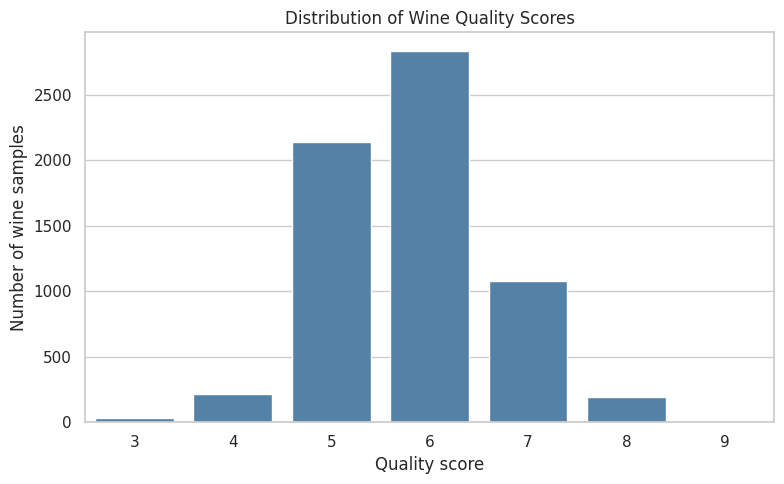

Quality score counts:


,Number of samples
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


Interpretation: inspect the bar heights to identify the most common quality scores and whether very low/high scores are rare.


In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", color="steelblue")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wine samples")
plt.tight_layout()
plt.show()

print("Quality score counts:")
display(df["quality"].value_counts().sort_index().to_frame("Number of samples"))
print("Interpretation: inspect the bar heights to identify the most common quality scores and whether very low/high scores are rare.")

### 2(b). Box plot of alcohol grouped by quality
The box shows the middle 50% of values; the line inside is the median. Points outside the whiskers may be potential outliers.

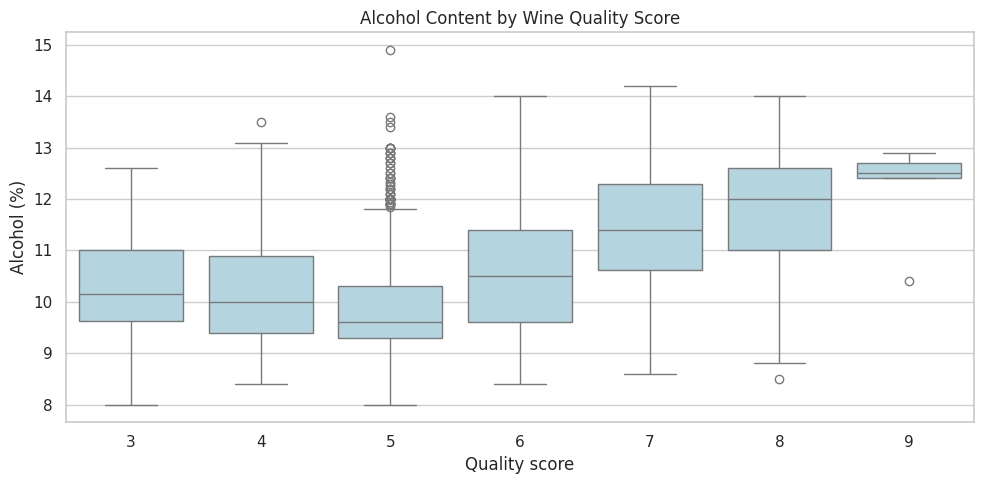

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="quality", y="alcohol", color="lightblue")
plt.title("Alcohol Content by Wine Quality Score")
plt.xlabel("Quality score")
plt.ylabel("Alcohol (%)")
plt.tight_layout()
plt.show()

### 2(c). Correlation heatmap for physicochemical attributes and quality

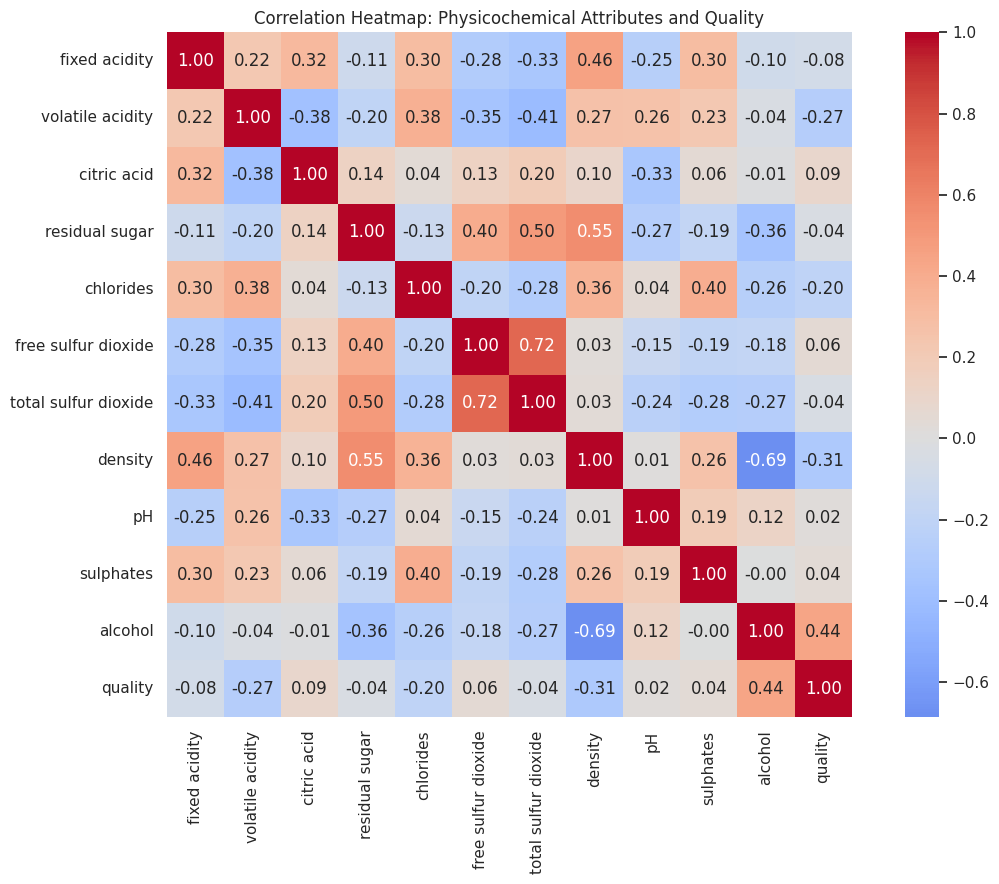

In [9]:
physicochemical_cols = [c for c in df.columns if c not in ["quality", "wine_type"]]
corr_df = df[physicochemical_cols + ["quality"]].corr(method="pearson")
plt.figure(figsize=(12, 9))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap: Physicochemical Attributes and Quality")
plt.tight_layout()
plt.show()

### 2(d). Two attributes most strongly associated with quality
Rank attributes by absolute Pearson correlation with quality. This identifies association, not causation.

In [10]:
quality_corr = corr_df["quality"].drop("quality")
top_two = quality_corr.reindex(quality_corr.abs().sort_values(ascending=False).index).head(2)
top_two_df = pd.DataFrame({
    "Pearson correlation with quality": top_two,
    "Direction": ["Positive" if v > 0 else "Negative" if v < 0 else "No linear association" for v in top_two.values]
})
display(top_two_df.round(4))
print("These two features have the largest absolute Pearson correlations with quality in the combined dataset.")

,Pearson correlation with quality,Direction
alcohol,0.4443,Positive
density,-0.3059,Negative


These two features have the largest absolute Pearson correlations with quality in the combined dataset.


## Task 3 — Predictive modelling
### 3(a–b). Multiple linear regression and 80:20 train-test split
Use the 11 physicochemical attributes as predictors and quality as the target. `random_state=42` makes the split reproducible.

In [11]:
X = df[physicochemical_cols]
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Number of predictors:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model trained successfully.")

Number of predictors: 11
Training samples: 5197
Testing samples: 1300
Model trained successfully.


### 3(c). Test-set evaluation metrics
MAE and RMSE are measured in quality-score points. MSE is in squared score points. R² measures how much test-set variation is explained by the model; it can be negative if predictions are worse than predicting the test mean.

In [12]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Test value": [mae, mse, rmse, r2]
})
display(metrics.round(4))

,Metric,Test value
0,MAE,0.5659
1,MSE,0.5467
2,RMSE,0.7394
3,R²,0.2598


### 3(d). Standardized regression coefficients and multicollinearity
Standardized coefficients are fitted after scaling each predictor. Their absolute magnitudes help compare relative influence, but correlated predictors can make individual coefficients unstable. We inspect VIF (Variance Inflation Factor); larger VIF values indicate stronger multicollinearity.

In [13]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

std_model = LinearRegression()
std_model.fit(X_train_std, y_train)

coef_table = pd.DataFrame({
    "Attribute": physicochemical_cols,
    "Standardized coefficient": std_model.coef_
})
coef_table["Absolute coefficient"] = coef_table["Standardized coefficient"].abs()
coef_table = coef_table.sort_values("Absolute coefficient", ascending=False)
display(coef_table.round(4))

# VIF computed from the predictor data. Add constant for statsmodels VIF calculation.
X_vif = sm.add_constant(X)
vif_values = []
for i, col in enumerate(X_vif.columns):
    if col == "const":
        continue
    vif_values.append({
        "Attribute": col,
        "VIF": variance_inflation_factor(X_vif.values, i)
    })
vif_table = pd.DataFrame(vif_values).sort_values("VIF", ascending=False)
display(vif_table.round(3))

top_predictors = coef_table.head(2)
print("Two predictors with the largest absolute standardized coefficients:")
display(top_predictors[["Attribute", "Standardized coefficient"]].round(4))
print("Interpret coefficient signs cautiously if the corresponding predictors have high VIF values.")

,Attribute,Standardized coefficient,Absolute coefficient
10,alcohol,0.3224,0.3224
3,residual sugar,0.2204,0.2204
1,volatile acidity,-0.2190,0.2190
7,density,-0.1773,0.1773
6,total sulfur dioxide,-0.1495,0.1495
5,free sulfur dioxide,0.1225,0.1225
9,sulphates,0.1202,0.1202
0,fixed acidity,0.1017,0.1017
8,pH,0.0771,0.0771
2,citric acid,-0.0208,0.0208


,Attribute,VIF
7,density,15.9150
3,residual sugar,7.2290
0,fixed acidity,4.8970
10,alcohol,4.7820
6,total sulfur dioxide,2.9380
8,pH,2.5370
5,free sulfur dioxide,2.1350
1,volatile acidity,1.9490
4,chlorides,1.6320
2,citric acid,1.6080


Two predictors with the largest absolute standardized coefficients:


,Attribute,Standardized coefficient
10,alcohol,0.3224
3,residual sugar,0.2204


Interpret coefficient signs cautiously if the corresponding predictors have high VIF values.


### 3(e). Actual versus predicted quality
Points close to the diagonal represent accurate predictions. Linear regression predicts continuous values, even though the recorded quality score is an integer.

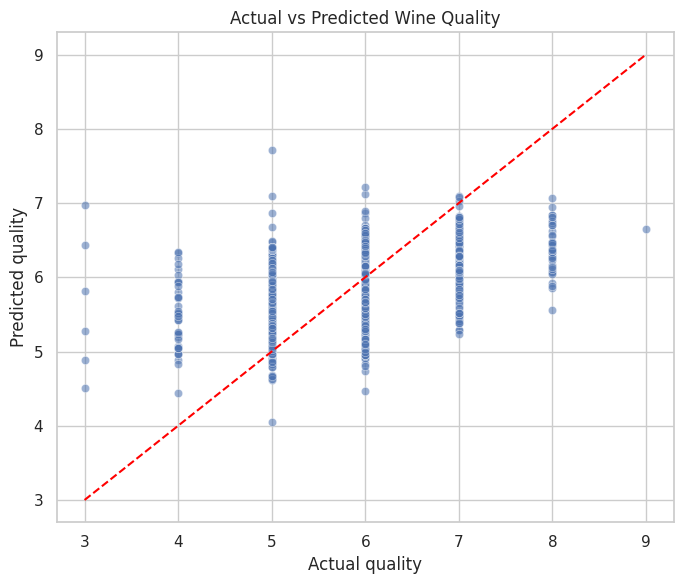

Model limitation: predictions tend to be pulled toward the average, and linear regression may not capture nonlinear relationships or subjective sensory factors.


In [14]:
pred_plot = pd.DataFrame({"Actual quality": y_test, "Predicted quality": y_pred})
plt.figure(figsize=(7, 6))
sns.scatterplot(data=pred_plot, x="Actual quality", y="Predicted quality", alpha=0.55)
min_val = min(pred_plot.min())
max_val = max(pred_plot.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="red")
plt.title("Actual vs Predicted Wine Quality")
plt.tight_layout()
plt.show()
print("Model limitation: predictions tend to be pulled toward the average, and linear regression may not capture nonlinear relationships or subjective sensory factors.")

## Task 4 — Business decision-making
### 4(a). Recommend two measurements for screening
The following cell generates recommendations from the observed absolute correlations with quality. Treat them as candidates for screening, not proof of causation.

In [15]:
screening_candidates = quality_corr.reindex(quality_corr.abs().sort_values(ascending=False).index).head(2)
print("Two measurements to investigate first:")
for feature, corr_value in screening_candidates.items():
    print(f"- {feature}: correlation = {corr_value:.3f} ({'positive' if corr_value > 0 else 'negative'})")

Two measurements to investigate first:
- alcohol: correlation = 0.444 (positive)
- density: correlation = -0.306 (negative)


### 4(b). Can regression replace sensory evaluation?
Use the actual test-set metrics above to support your recommendation. A low error is helpful, but the model should not replace sensory evaluation without independent validation and a clear acceptable error threshold.

In [16]:
print(f"Test MAE: {mae:.3f} quality points")
print(f"Test RMSE: {rmse:.3f} quality points")
print(f"Test R²: {r2:.3f}")

if r2 < 0.3:
    reliability_comment = "The model explains a limited share of test-set variation, so it should not replace sensory evaluation."
elif r2 < 0.6:
    reliability_comment = "The model has moderate explanatory power and may support preliminary screening, but should not replace sensory evaluation."
else:
    reliability_comment = "The model explains a substantial share of test-set variation, but further validation is still needed before considering replacement of sensory evaluation."
print(reliability_comment)
print("Business recommendation: use the model as a supplementary screening tool, not as the sole quality decision-maker.")

Test MAE: 0.566 quality points
Test RMSE: 0.739 quality points
Test R²: 0.260
The model explains a limited share of test-set variation, so it should not replace sensory evaluation.
Business recommendation: use the model as a supplementary screening tool, not as the sole quality decision-maker.


### 4(c). Two limitations
1. **Subjective/limited target:** Quality scores are sensory ratings and may contain human subjectivity; laboratory measurements cannot capture every aspect of taste, aroma, or consumer preference.
2. **Model and dataset limitations:** A linear model assumes additive linear relationships and may miss nonlinear effects and interactions. The train-test split is a single evaluation, so performance should be checked on new, independent wine samples before deployment.

## Final conclusion

In [17]:
print("CONCLUSION")
print(f"The combined dataset contains {len(df):,} wine samples ({len(red):,} red and {len(white):,} white).")
print(f"Alcohol-quality Pearson correlation: {alcohol_r:.3f}.")
print(f"Two strongest quality associations: {', '.join(top_two.index.tolist())}.")
print(f"Linear regression test metrics: MAE={mae:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}.")
print("The model can help identify patterns and support preliminary laboratory screening, but should not fully replace sensory evaluation without independent validation.")

CONCLUSION
The combined dataset contains 6,497 wine samples (1,599 red and 4,898 white).
Alcohol-quality Pearson correlation: 0.444.
Two strongest quality associations: alcohol, density.
Linear regression test metrics: MAE=0.566, RMSE=0.739, R²=0.260.
The model can help identify patterns and support preliminary laboratory screening, but should not fully replace sensory evaluation without independent validation.
